# Wind forecast accuracy: January 2026 day-ahead decisions

**What this notebook answers.** For every purchase decision made in January 2026 (delivery days 2 Jan – 1 Feb):
how good was the latest national wind forecast available at the auction gate closure, how does its error depend
on lead time, wind level and hour, and how much wind could the desk safely bank on?

**How it works.** Every number comes from the tested `winddesk.analytics` package, the same code the web app's API
uses, applied to the committed, validated snapshot in `data/snapshot/`. Nothing is re-implemented here. Each section
starts with a question and ends with a one-line **Answer** built from the computed values.

**Conventions.** `error = forecast − actual` (positive = over-forecast = wind **shortfall**). Times are computed in
UTC and labelled in UK time (GMT in January). Decision cutoffs: EPEX 09:20 and N2EX 09:50 on the day before
delivery. Buffers and firm wind are leave-one-day-out (LODO): a day's buffer never sees that day's outcome.

Re-run with `make notebook`. The last section rewrites `docs/INSIGHTS.md`.

In [1]:
from datetime import date

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from winddesk.analytics import accuracy as acc
from winddesk.analytics.buffers import calibrate
from winddesk.analytics.decision import decision_day
from winddesk.analytics.metrics import compute_metrics
from winddesk.analytics.narrative import decision_summary
from winddesk.analytics.pilot import AUCTIONS, CONFIDENCES
from winddesk.analytics.selection import (
    coverage,
    decision_pool,
    hourly_mean_actuals,
    select_at_horizon,
)
from winddesk.analytics.timeutil import LONDON, delivery_day_targets, to_uk_label
from winddesk.config import REPO_ROOT
from winddesk.store import get_store

store = get_store()
pools = store.pools  # decision pairs per auction: {"epex": …, "n2ex": …}
C = 0.9  # headline confidence

# Semantic colours, identical to the app (UI_SPEC §1).
ACTUAL, FORECAST, SHORTFALL, SURPLUS, CUTOFF, MUTED = (
    "#2563EB",
    "#16A34A",
    "#D97706",
    "#64748B",
    "#334155",
    "#CBD5E1",
)
plt.rcParams.update(
    {
        "figure.figsize": (11, 3.6),
        "figure.dpi": 100,
        "axes.grid": True,
        "grid.alpha": 0.25,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "font.size": 10,
        "axes.titlesize": 11,
        "axes.titleweight": "bold",
        "legend.frameon": False,
    }
)


def answer(text: str) -> None:
    display(Markdown(f"**Answer:** {text}"))


def mw(x: float) -> str:
    return f"{x:,.0f} MW"


def signed_mw(x: float) -> str:
    return f"{x:+,.0f} MW"


def uk(ts: pd.Timestamp) -> str:
    return to_uk_label(ts)


def day_label(d: date) -> str:
    return to_uk_label(pd.Timestamp(d.isoformat(), tz=LONDON), with_time=False)


print(
    f"Snapshot {store.snapshot_id}: {len(store.forecasts):,} forecast rows, "
    f"{len(store.actuals):,} half-hourly actuals, {len(store.delivery_days)} delivery days."
)

Snapshot ac22a4140bca: 14,847 forecast rows, 1,536 half-hourly actuals, 31 delivery days.


## 1. Data overview and quality

**Question:** What data do we have, is it complete, and did ingestion flag anything?

,id,status,message
0,runs_per_day,ok,8 runs on every one of 34 publish days
1,rows_per_run,ok,73 hourly points in every one of 272 runs
2,run_times,warn,1 run(s) off the nominal schedule: 2026-01-15T...
3,forecast_values,ok,No null or negative forecast values
4,lead_range,ok,Lead times 0.5–66.5 h; 57 rows from off-schedu...
5,periods_per_day,ok,All half-hourly periods present on 32 settleme...
6,actual_values,ok,No null or negative actual values
7,decision_coverage_epex,ok,EPEX SPOT GB Day-Ahead (09:20): the decision r...
8,decision_coverage_n2ex,ok,Nord Pool N2EX Day-Ahead (09:50): the decision...


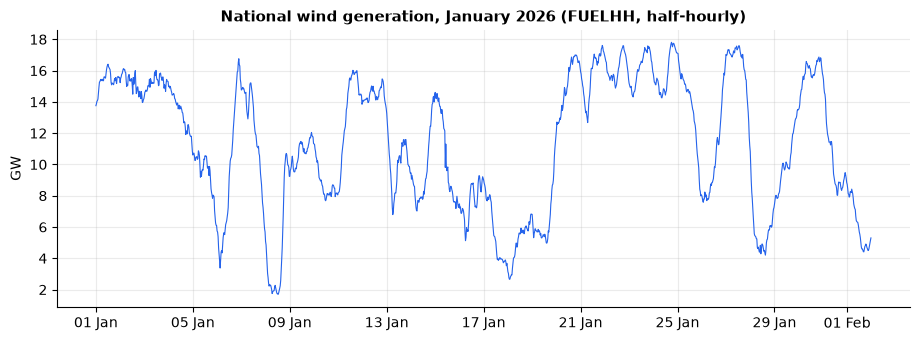

In [2]:
checks = {c["id"]: c for c in store.quality["checks"]}
display(pd.DataFrame(store.quality["checks"])[["id", "status", "message"]])

a = store.actuals
fig, ax = plt.subplots()
ax.plot(a["target_time"], a["actual_mw"] / 1000, color=ACTUAL, lw=0.8)
ax.set(title="National wind generation, January 2026 (FUELHH, half-hourly)", ylabel="GW")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
plt.show()

In [3]:
summary = store.quality["summary"]
off_schedule = [uk(pd.Timestamp(t)) for t in checks["run_times"]["details"]["off_schedule"]]
warnings = [c["id"] for c in checks.values() if c["status"] != "ok"]
answer(
    f"{summary['forecast_runs']} forecast runs ({summary['forecast_rows']:,} rows) and "
    f"{summary['actual_rows']:,} half-hourly actuals, with no missing periods, duplicates, nulls or negative values. "
    f"Wind ranged from {a['actual_mw'].min() / 1000:.1f} to {a['actual_mw'].max() / 1000:.1f} GW. "
    f"The only warning ({', '.join(warnings)}) is one run published off-schedule: {', '.join(off_schedule)} "
    f"(UK time, which equals UTC in January), in the 11:30 slot."
)

**Answer:** 272 forecast runs (14,847 rows) and 1,536 half-hourly actuals, with no missing periods, duplicates, nulls or negative values. Wind ranged from 1.7 to 17.8 GW. The only warning (run_times) is one run published off-schedule: Thu 15 Jan 12:25 (UK time, which equals UTC in January), in the 11:30 slot.

## 2. Publish cadence and lead-time coverage

**Question:** Do the facts we sampled on two days (DATA §1.2) hold for the whole window, and how far ahead does a
forecast exist for every hour?

,Fact (DATA §1.2),Expected,Observed
0,Runs per publish day,8,8–8 on all 34 days
1,Points per run before the lead filter,73,73 points: 272 runs
2,Run times (UTC),02:30 04:30 07:30 09:30 11:30 15:30 18:30 22:30,02:30 04:30 07:30 09:30 11:30 12:25 15:30 18:3...
3,Lead times kept (h),0.5–66.5,0.5–66.5
4,EPEX (09:20) decision run,D−1 07:30,D−1 07:30 on all 31 days
5,N2EX (09:50) decision run,D−1 09:30,D−1 09:30 on all 31 days


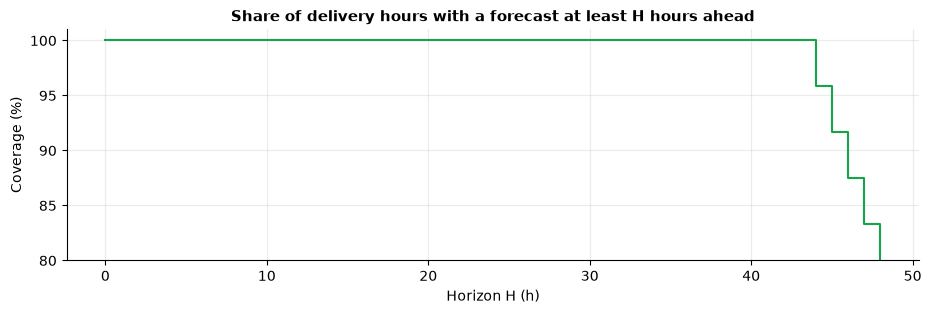

In [4]:
runs = pd.Series(store.forecasts["publish_time"].unique())
per_day = runs.dt.date.value_counts()
lead = store.forecasts["lead_h"]


def decision_runs(auction: str) -> str:
    pool = pools[auction]
    published = pool.groupby("delivery_date")["publish_time"].first()
    days_before = {(d - p.date()).days for d, p in published.items()}
    times = sorted({f"{p:%H:%M}" for p in published})
    return f"D−{', '.join(map(str, days_before))} {', '.join(times)} on all {len(published)} days"


facts = pd.DataFrame(
    [
        (
            "Runs per publish day",
            "8",
            f"{per_day.min()}–{per_day.max()} on all {len(per_day)} days",
        ),
        (
            "Points per run before the lead filter",
            "73",
            "; ".join(
                f"{k} points: {v} runs"
                for k, v in checks["rows_per_run"]["details"]["histogram"].items()
            ),
        ),
        (
            "Run times (UTC)",
            "02:30 04:30 07:30 09:30 11:30 15:30 18:30 22:30",
            " ".join(checks["run_times"]["details"]["observed_utc"]),
        ),
        ("Lead times kept (h)", "0.5–66.5", f"{lead.min():g}–{lead.max():g}"),
        ("EPEX (09:20) decision run", "D−1 07:30", decision_runs("epex")),
        ("N2EX (09:50) decision run", "D−1 09:30", decision_runs("n2ex")),
    ],
    columns=["Fact (DATA §1.2)", "Expected", "Observed"],
)
display(facts)

targets = pd.Series([t for d in store.delivery_days for t in delivery_day_targets(d)])
horizons = np.arange(0, 48.5, 0.5)
cov = pd.Series(
    [coverage(select_at_horizon(store.forecasts, targets, h)).pct for h in horizons], index=horizons
)

fig, ax = plt.subplots(figsize=(11, 3))
ax.step(cov.index, cov.values, where="post", color=FORECAST)
ax.set(
    title="Share of delivery hours with a forecast at least H hours ahead",
    xlabel="Horizon H (h)",
    ylabel="Coverage (%)",
    ylim=(80, 101),
)
plt.show()

In [5]:
full_up_to = cov[cov == 100].index.max()
answer(
    f"All confirmed: 8 runs on every publish day, 73 points in every run, and the EPEX and N2EX decision runs are "
    f"always the D−1 07:30 and 09:30 runs. Kept leads span {lead.min():g}–{lead.max():g} h. Every delivery hour has "
    f"a forecast up to {full_up_to:g} h ahead; at 48 h coverage is {cov[48.0]:.1f}%, because no run reaches the "
    f"22:00–23:00 UTC hours that far out."
)

**Answer:** All confirmed: 8 runs on every publish day, 73 points in every run, and the EPEX and N2EX decision runs are always the D−1 07:30 and 09:30 runs. Kept leads span 0.5–66.5 h. Every delivery hour has a forecast up to 43.5 h ahead; at 48 h coverage is 79.2%, because no run reaches the 22:00–23:00 UTC hours that far out.

## 3. Error vs lead time (all pairs)

**Question:** How fast does forecast error grow with lead time, and where do the day-ahead decisions sit?

Population: every run × every target it covers (DATA §5.6), grouped in 1-hour bins of *actual* lead time.

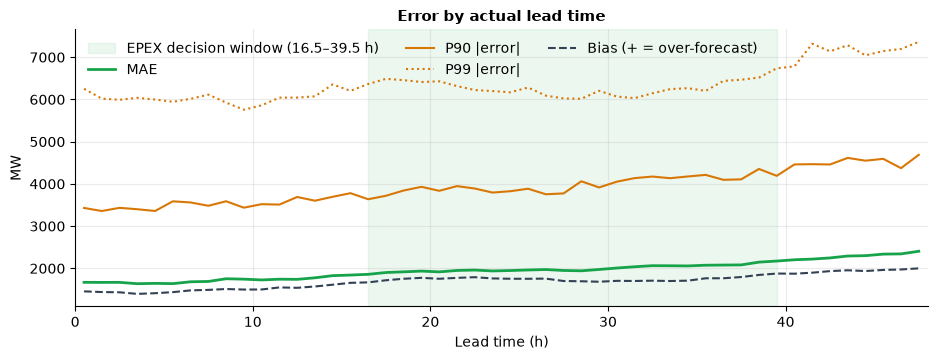

,n,mae_mw,rmse_mw,bias_mw,p90_abs_mw,p99_abs_mw
lead_h,,,,,,
0.5,248,1669.0,2123.0,1455.0,3430.0,6252.0
1.5,248,1667.0,2122.0,1439.0,3358.0,6018.0
12.5,248,1740.0,2223.0,1539.0,3690.0,6043.0
24.5,248,1949.0,2414.0,1754.0,3826.0,6169.0
36.5,248,2078.0,2589.0,1766.0,4096.0,6439.0
47.5,217,2405.0,2963.0,2000.0,4688.0,7362.0


In [6]:
lc = store.lead_curves[1.0].set_index("lead_h")
fig, ax = plt.subplots()
ax.axvspan(16.5, 39.5, color=FORECAST, alpha=0.08, label="EPEX decision window (16.5–39.5 h)")
ax.plot(lc.index, lc["mae_mw"], color=FORECAST, lw=2, label="MAE")
ax.plot(lc.index, lc["p90_abs_mw"], color=SHORTFALL, label="P90 |error|")
ax.plot(lc.index, lc["p99_abs_mw"], color=SHORTFALL, ls=":", label="P99 |error|")
ax.plot(lc.index, lc["bias_mw"], color=CUTOFF, ls="--", label="Bias (+ = over-forecast)")
ax.set(title="Error by actual lead time", xlabel="Lead time (h)", ylabel="MW", xlim=(0, 48))
ax.legend(ncols=3, loc="upper left")
plt.show()

LEADS = [0.5, 1.5, 12.5, 24.5, 36.5, 47.5]
display(lc.loc[LEADS, ["n", "mae_mw", "rmse_mw", "bias_mw", "p90_abs_mw", "p99_abs_mw"]].round(0))

In [7]:
answer(
    f"MAE grows from {mw(lc.at[1.5, 'mae_mw'])} at 1.5 h to {mw(lc.at[24.5, 'mae_mw'])} at 24.5 h and "
    f"{mw(lc.at[47.5, 'mae_mw'])} at 47.5 h. But the forecast is already biased by {signed_mw(lc.at[0.5, 'bias_mw'])} "
    f"only 0.5 h ahead, so most of the error is a persistent level offset between forecast and metered wind, not "
    f"uncertainty that builds with lead time."
)

**Answer:** MAE grows from 1,667 MW at 1.5 h to 1,949 MW at 24.5 h and 2,405 MW at 47.5 h. But the forecast is already biased by +1,455 MW only 0.5 h ahead, so most of the error is a persistent level offset between forecast and metered wind, not uncertainty that builds with lead time.

## 4. Decision-mode error: EPEX vs N2EX

**Question:** How accurate is the forecast the desk actually had at each auction's gate closure, and is the
two-hours-fresher 09:30 run (available to N2EX bidders) worth much?

,EPEX SPOT GB Day-Ahead,Nord Pool N2EX Day-Ahead
n,744.0,744.0
mae_mw,2022.5,1995.6
rmse_mw,2497.4,2498.8
bias_mw,1745.9,1728.0
wape_pct,17.9,17.7
p50_abs_mw,1655.0,1625.5
p90_abs_mw,4154.4,4183.9
p99_abs_mw,6139.5,6212.8
p90_shortfall_mw,4154.4,4183.9
max_shortfall_mw,6894.0,6857.0


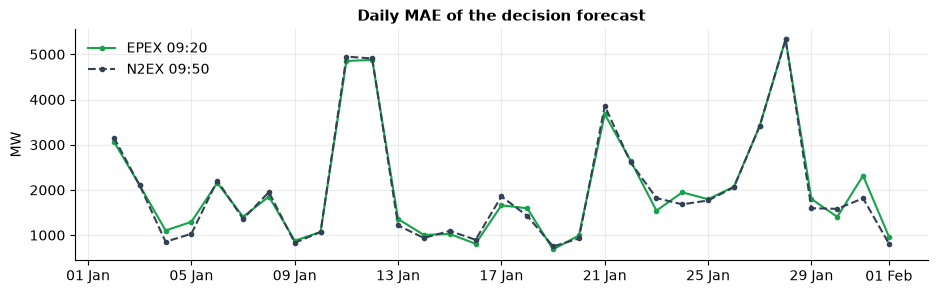

In [8]:
metrics = {a: compute_metrics(pools[a]) for a in pools}
rows = [
    "n",
    "mae_mw",
    "rmse_mw",
    "bias_mw",
    "wape_pct",
    "p50_abs_mw",
    "p90_abs_mw",
    "p99_abs_mw",
    "p90_shortfall_mw",
    "max_shortfall_mw",
]
table = pd.DataFrame(
    {a.label: [getattr(metrics[a.id], r) for r in rows] for a in AUCTIONS}, index=rows
)
display(table.round(1))

cmp = acc.auction_comparison(pools["epex"], pools["n2ex"])
daily_mae = pd.DataFrame(
    {a: acc.daily(pools[a]).set_index("delivery_date")["mae_mw"] for a in pools}
)
fig, ax = plt.subplots(figsize=(11, 3))
ax.plot(daily_mae.index, daily_mae["epex"], color=FORECAST, marker="o", ms=3, label="EPEX 09:20")
ax.plot(
    daily_mae.index, daily_mae["n2ex"], color=CUTOFF, marker="o", ms=3, ls="--", label="N2EX 09:50"
)
ax.set(title="Daily MAE of the decision forecast", ylabel="MW")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
ax.legend()
plt.show()

In [9]:
e, n = metrics["epex"], metrics["n2ex"]
answer(
    f"At the EPEX cutoff (16.5–39.5 h ahead) the forecast is off by {mw(e.mae_mw)} on average "
    f"(WAPE {e.wape_pct:.1f}%) and runs {signed_mw(e.bias_mw)} high. The two-hours-fresher N2EX run "
    + (
        f"lowers MAE by only {-cmp.mae_change_pct:.1f}%"
        if cmp.mae_change_pct < 0
        else f"raises MAE by {cmp.mae_change_pct:.1f}%"
    )
    + f" (to {mw(n.mae_mw)}), and its P90 shortfall is {mw(n.p90_shortfall_mw)} vs {mw(e.p90_shortfall_mw)}: "
    f"timing within the morning hardly matters."
)

**Answer:** At the EPEX cutoff (16.5–39.5 h ahead) the forecast is off by 2,022 MW on average (WAPE 17.9%) and runs +1,746 MW high. The two-hours-fresher N2EX run lowers MAE by only 1.3% (to 1,996 MW), and its P90 shortfall is 4,184 MW vs 4,154 MW: timing within the morning hardly matters.

## 5. Error distribution: skew and tails

**Question:** Are over-forecasts (shortfalls) or under-forecasts (surpluses) more common and more extreme?

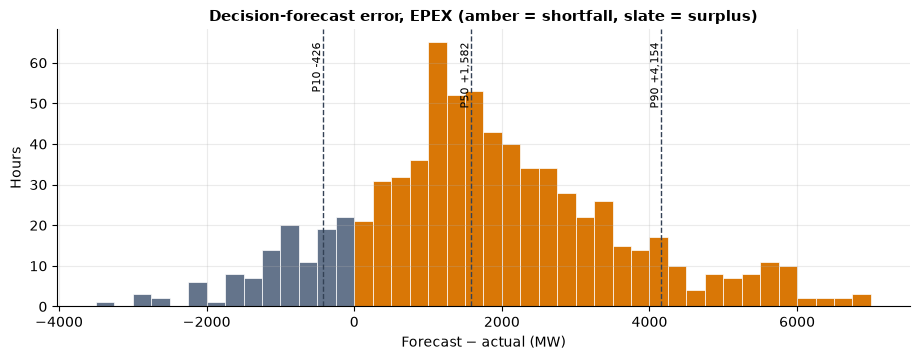

,EPEX
share over-forecast (%),84.68
skewness,0.30
P1 (MW),-2188.39
P99 (MW),6139.48
largest shortfall (MW),6894.00
largest surplus (MW),3389.00


In [10]:
err = pools["epex"]["error_mw"]
dist = acc.error_distribution(err)
edges = np.array(dist.bin_edges_mw)
fig, ax = plt.subplots()
ax.bar(
    edges[:-1],
    dist.counts,
    width=np.diff(edges),
    align="edge",
    color=[SHORTFALL if left >= 0 else SURPLUS for left in edges[:-1]],
    edgecolor="white",
    lw=0.5,
)
for q, value in (("P10", dist.p10_mw), ("P50", dist.p50_mw), ("P90", dist.p90_mw)):
    ax.axvline(value, color=CUTOFF, ls="--", lw=1)
    ax.annotate(
        f"{q} {value:+,.0f}",
        (value, max(dist.counts)),
        rotation=90,
        va="top",
        ha="right",
        fontsize=8,
    )
ax.set(
    title="Decision-forecast error, EPEX (amber = shortfall, slate = surplus)",
    xlabel="Forecast − actual (MW)",
    ylabel="Hours",
)
plt.show()

tails = pd.Series(
    {
        "share over-forecast (%)": 100 * (err > 0).mean(),
        "skewness": err.skew(),
        "P1 (MW)": err.quantile(0.01),
        "P99 (MW)": err.quantile(0.99),
        "largest shortfall (MW)": err.max(),
        "largest surplus (MW)": -err.min(),
    }
)
display(tails.round(2).to_frame("EPEX"))

In [11]:
answer(
    f"Shortfalls dominate: wind came in below the forecast in {tails['share over-forecast (%)']:.0f}% of decision hours, "
    f"the median error is {signed_mw(dist.p50_mw)}, and the worst shortfall ({mw(tails['largest shortfall (MW)'])}) is "
    f"larger than the worst surplus ({mw(tails['largest surplus (MW)'])})."
)

**Answer:** Shortfalls dominate: wind came in below the forecast in 85% of decision hours, the median error is +1,582 MW, and the worst shortfall (6,894 MW) is larger than the worst surplus (3,389 MW).

## 6. Error by wind level and by hour of day

**Question:** Does the error depend on how windy the forecast says it will be, or on the time of day?

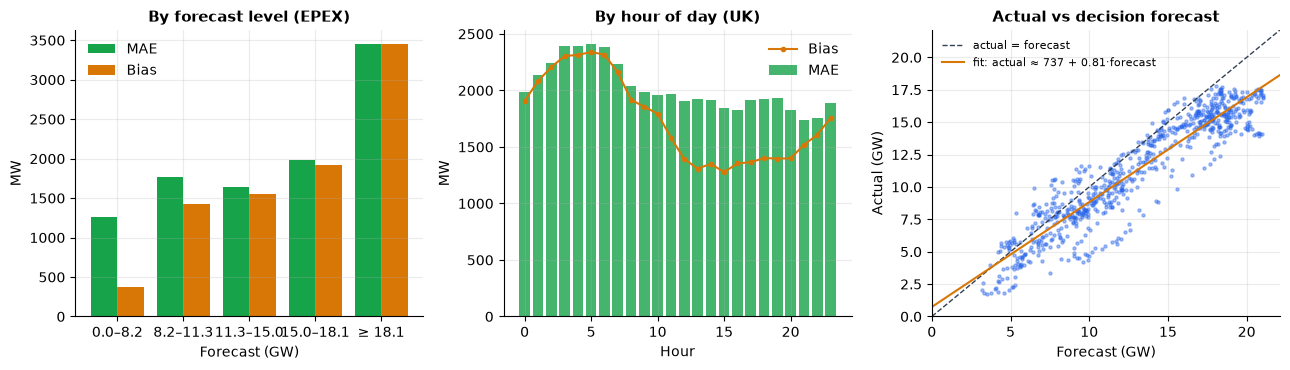

,n,mae_mw,bias_mw,p80_shortfall_mw,p90_shortfall_mw,p95_shortfall_mw,achieved_pct
level_gw,,,,,,,
0.0–8.2,148,1258.1,370.9,1656.6,1970.3,2488.7,88.5
8.2–11.3,150,1773.4,1427.0,2345.6,3719.0,5024.5,84.7
11.3–15.0,148,1640.9,1558.1,2574.4,3105.9,5570.0,87.8
15.0–18.1,150,1986.2,1918.0,2651.2,3317.5,4562.3,88.7
≥ 18.1,148,3457.7,3457.7,4339.8,5375.8,5895.4,85.1


In [12]:
levels = acc.by_level(pools["epex"], store.calibrations[("epex", C)])
hours = acc.by_hour(pools["epex"])
level_names = [
    f"{r.forecast_from_mw / 1000:.1f}–{r.forecast_to_mw / 1000:.1f}"
    if pd.notna(r.forecast_to_mw)
    else f"≥ {r.forecast_from_mw / 1000:.1f}"
    for r in levels.itertuples()
]
ep = pools["epex"]
slope, intercept = np.polyfit(ep["forecast_mw"], ep["actual_mw"], 1)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
x = np.arange(len(levels))
axes[0].bar(x - 0.2, levels["mae_mw"], 0.4, color=FORECAST, label="MAE")
axes[0].bar(x + 0.2, levels["bias_mw"], 0.4, color=SHORTFALL, label="Bias")
axes[0].set(
    title="By forecast level (EPEX)",
    xticks=x,
    xticklabels=level_names,
    xlabel="Forecast (GW)",
    ylabel="MW",
)
axes[0].legend()
axes[1].bar(hours["hour_uk"], hours["mae_mw"], color=FORECAST, alpha=0.8, label="MAE")
axes[1].plot(hours["hour_uk"], hours["bias_mw"], color=SHORTFALL, marker="o", ms=3, label="Bias")
axes[1].set(title="By hour of day (UK)", xlabel="Hour", ylabel="MW")
axes[1].legend()
lim = [0, max(ep["forecast_mw"].max(), ep["actual_mw"].max()) / 1000 * 1.05]
axes[2].scatter(ep["forecast_mw"] / 1000, ep["actual_mw"] / 1000, s=5, alpha=0.4, color=ACTUAL)
axes[2].plot(lim, lim, color=CUTOFF, ls="--", lw=1, label="actual = forecast")
axes[2].plot(
    lim,
    [intercept / 1000 + slope * v for v in lim],
    color=SHORTFALL,
    lw=1.5,
    label=f"fit: actual ≈ {intercept:,.0f} + {slope:.2f}·forecast",
)
axes[2].set(
    title="Actual vs decision forecast",
    xlabel="Forecast (GW)",
    ylabel="Actual (GW)",
    xlim=lim,
    ylim=lim,
)
axes[2].legend(fontsize=8)
plt.tight_layout()
plt.show()

display(
    levels.assign(level_gw=level_names)
    .set_index("level_gw")
    .drop(columns=["forecast_from_mw", "forecast_to_mw"])
    .round(1)
)

In [13]:
answer(
    f"Wind level matters far more than the hour: bias rises from {signed_mw(levels['bias_mw'].iloc[0])} when the "
    f"forecast is below {levels['forecast_to_mw'].iloc[0] / 1000:.1f} GW to {signed_mw(levels['bias_mw'].iloc[-1])} "
    f"above {levels['forecast_from_mw'].iloc[-1] / 1000:.1f} GW (actual ≈ {intercept:,.0f} + {slope:.2f} × forecast, "
    f"r = {np.corrcoef(ep['forecast_mw'], ep['actual_mw'])[0, 1]:.2f}), while hourly MAE stays within "
    f"{mw(hours['mae_mw'].min())}–{mw(hours['mae_mw'].max())}. The forecast tracks the shape of wind well but "
    f"overstates its level, most in windy hours. This is consistent with transmission constraints curtailing output, "
    f"or with the two datasets covering different farms; Elexon's dataset descriptions do not say which, so it is "
    f"reported as a hypothesis."
)

**Answer:** Wind level matters far more than the hour: bias rises from +371 MW when the forecast is below 8.2 GW to +3,458 MW above 18.1 GW (actual ≈ 737 + 0.81 × forecast, r = 0.93), while hourly MAE stays within 1,736 MW–2,414 MW. The forecast tracks the shape of wind well but overstates its level, most in windy hours. This is consistent with transmission constraints curtailing output, or with the two datasets covering different farms; Elexon's dataset descriptions do not say which, so it is reported as a hypothesis.

## 7. Buffer calibration (LODO): does the P90 firm-wind line hold?

**Question:** If the desk had banked only "firm wind" (forecast minus a buffer learned from *other* days), how often
would actual wind have met it? Target: within ±5 percentage points of the confidence level (PRD §3).

,auction,target %,conditional achieved %,simple achieved %,avg conditional buffer (MW),"simple buffer, avg (MW)"
0,epex,80.0,77.7,79.7,2710.6,3121.4
1,epex,90.0,87.0,88.6,3508.6,4142.0
2,epex,95.0,92.6,93.3,4660.1,5261.6
3,n2ex,80.0,78.5,79.6,2643.6,3078.3
4,n2ex,90.0,87.2,88.8,3551.3,4193.6
5,n2ex,95.0,92.3,93.4,4695.6,5295.0


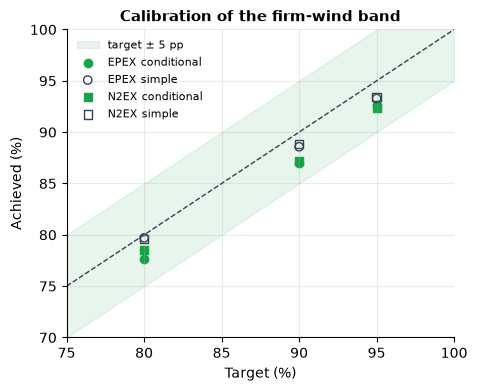

In [14]:
rows = []
for a in AUCTIONS:
    for c in CONFIDENCES:
        conditional = store.calibrations[(a.id, c)]
        simple = calibrate(pools[a.id], c, "simple_lodo")
        rows.append(
            {
                "auction": a.id,
                "target %": 100 * c,
                "conditional achieved %": conditional.achieved_pct,
                "simple achieved %": simple.achieved_pct,
                "avg conditional buffer (MW)": conditional.hours["buffer_mw"].mean(),
                "simple buffer, avg (MW)": simple.hours["buffer_mw"].mean(),
            }
        )
calibration = pd.DataFrame(rows)
display(calibration.round(1))

fig, ax = plt.subplots(figsize=(5, 4))
t = np.array([75, 100])
ax.fill_between(t, t - 5, t + 5, color=FORECAST, alpha=0.1, label="target ± 5 pp")
ax.plot(t, t, color=CUTOFF, ls="--", lw=1)
for a, marker in (("epex", "o"), ("n2ex", "s")):
    sub = calibration[calibration["auction"] == a]
    ax.scatter(
        sub["target %"],
        sub["conditional achieved %"],
        marker=marker,
        color=FORECAST,
        label=f"{a.upper()} conditional",
    )
    ax.scatter(
        sub["target %"],
        sub["simple achieved %"],
        marker=marker,
        facecolor="none",
        edgecolor=CUTOFF,
        label=f"{a.upper()} simple",
    )
ax.set(
    title="Calibration of the firm-wind band",
    xlabel="Target (%)",
    ylabel="Achieved (%)",
    xlim=(75, 100),
    ylim=(70, 100),
)
ax.legend(fontsize=8)
plt.show()

In [15]:
cal90 = calibration[calibration["target %"] == 90].set_index("auction")
within = (calibration["conditional achieved %"] - calibration["target %"]).abs().le(5).all()
answer(
    f"{'Yes' if within else 'Not fully'}: the P90 firm-wind line held in {cal90.at['epex', 'conditional achieved %']:.1f}% "
    f"of EPEX decision hours and {cal90.at['n2ex', 'conditional achieved %']:.1f}% for N2EX (target 90%), and the 80% and "
    f"95% bands are {'also ' if within else ''}within ±5 pp. It runs a little under target, as expected from one month of "
    f"leave-one-day-out data. Conditioning the buffer on wind level holds back "
    f"{mw(cal90.at['epex', 'simple buffer, avg (MW)'] - cal90.at['epex', 'avg conditional buffer (MW)'])} less on average "
    f"({mw(cal90.at['epex', 'avg conditional buffer (MW)'])} vs {mw(cal90.at['epex', 'simple buffer, avg (MW)'])} for one flat "
    f"buffer) at the cost of {cal90.at['epex', 'simple achieved %'] - cal90.at['epex', 'conditional achieved %']:.1f} pp of "
    f"coverage ({cal90.at['epex', 'conditional achieved %']:.1f}% vs {cal90.at['epex', 'simple achieved %']:.1f}%): a "
    f"trade-off to agree with the desk, not a free gain."
)

**Answer:** Yes: the P90 firm-wind line held in 87.0% of EPEX decision hours and 87.2% for N2EX (target 90%), and the 80% and 95% bands are also within ±5 pp. It runs a little under target, as expected from one month of leave-one-day-out data. Conditioning the buffer on wind level holds back 633 MW less on average (3,509 MW vs 4,142 MW for one flat buffer) at the cost of 1.6 pp of coverage (87.0% vs 88.6%): a trade-off to agree with the desk, not a free gain.

## 8. Alignment sensitivity: period starting at H vs hourly mean

**Question:** The app compares the hourly forecast at H with the settlement period *starting* at H (ADR-0004).
Would comparing with the mean of the two half-hours in hour H change any headline conclusion?

In [16]:
hourly = hourly_mean_actuals(store.actuals)
alt_pools = {
    a.id: decision_pool(store.forecasts, hourly, store.delivery_days, a.cutoff_local)
    for a in AUCTIONS
}


def headline(pool: pd.DataFrame) -> dict[str, float]:
    m = compute_metrics(pool)
    return {
        "MAE (MW)": m.mae_mw,
        "bias (MW)": m.bias_mw,
        "P90 shortfall (MW)": m.p90_shortfall_mw,
        "WAPE (%)": m.wape_pct,
        "P90 achieved (%)": calibrate(pool, C).achieved_pct,
    }


sens = pd.DataFrame(
    {
        (a, label): headline(p)
        for a in pools
        for label, p in (("start of hour (app)", pools[a]), ("hourly mean", alt_pools[a]))
    }
).T
display(sens.round(1))

# The headline conclusions, re-evaluated under the alternative alignment.
conclusions = {}
for name, pp in (("app", pools), ("hourly mean", alt_pools)):
    m_e, m_n = compute_metrics(pp["epex"]), compute_metrics(pp["n2ex"])
    cals = [calibrate(pp[a], c).achieved_pct - 100 * c for a in pp for c in CONFIDENCES]
    conclusions[name] = {
        "forecast runs high (bias > +1 GW)": m_e.bias_mw > 1000 and m_n.bias_mw > 1000,
        "N2EX is not materially better (|ΔMAE| < 5%)": abs(
            100 * (m_n.mae_mw - m_e.mae_mw) / m_e.mae_mw
        )
        < 5,
        "firm-wind bands within ±5 pp": all(abs(x) <= 5 for x in cals),
    }
conclusions = pd.DataFrame(conclusions)
display(conclusions)

MAE (MW)  bias (MW)  P90 shortfall (MW)  WAPE (%)  \
epex start of hour (app)    2022.5     1745.9              4154.4      17.9   
     hourly mean            2038.9     1747.9              4097.9      18.1   
n2ex start of hour (app)    1995.6     1728.0              4183.9      17.7   
     hourly mean            2013.0     1729.9              4143.8      17.8   

                          P90 achieved (%)  
epex start of hour (app)              87.0  
     hourly mean                      87.6  
n2ex start of hour (app)              87.2  
     hourly mean                      87.6

,app,hourly mean
forecast runs high (bias > +1 GW),True,True
N2EX is not materially better (|ΔMAE| < 5%),True,True
firm-wind bands within ±5 pp,True,True


In [17]:
d_mae = (
    sens.loc[("epex", "hourly mean"), "MAE (MW)"]
    - sens.loc[("epex", "start of hour (app)"), "MAE (MW)"]
)
changed = [
    c for c in conclusions.index if conclusions.at[c, "app"] != conclusions.at[c, "hourly mean"]
]
answer(
    f"Using the hourly mean changes EPEX MAE by {d_mae:+,.0f} MW "
    f"({100 * d_mae / sens.loc[('epex', 'start of hour (app)'), 'MAE (MW)']:+.1f}%) and leaves the bias and calibration "
    f"essentially unchanged; "
    + (
        "no headline conclusion changes."
        if not changed
        else f"these conclusions change: {', '.join(changed)}."
    )
)

**Answer:** Using the hourly mean changes EPEX MAE by +16 MW (+0.8%) and leaves the bias and calibration essentially unchanged; no headline conclusion changes.

## 9. Biggest misses and three story days

**Question:** Which hours and days were worst, what did the forecast evolution look like, and which days best
illustrate the product?

Story-day rules (EPEX, 90%, LODO):
1. **Worst miss:** the delivery day with the highest daily MAE.
2. **Typical day:** the day whose MAE is closest to the median daily MAE.
3. **Buffer did its job:** among the windiest quarter of days (by forecast energy), the day where wind fell furthest
   below forecast while firm wind still held in at least 22 of 24 hours.

In [18]:
display(
    acc.worst_hours(pools["epex"], 10)
    .assign(target_uk=lambda d: d["target_time"].map(uk), lead_h=lambda d: d["lead_h"])[
        ["target_uk", "forecast_mw", "actual_mw", "error_mw", "lead_h"]
    ]
    .round(0)
)

results = {
    d: decision_day(
        store.forecasts,
        store.actuals,
        pools["epex"],
        d,
        auction="epex",
        cutoff_local=store.auctions["epex"].cutoff_local,
        confidence=C,
    )
    for d in store.delivery_days
}
kpis = pd.DataFrame(
    {
        d: {
            "mae_mw": r.kpis.mae_mw,
            "forecast_gwh": r.kpis.forecast_mwh / 1000,
            "actual_gwh": r.kpis.actual_mwh / 1000,
            "energy_error_pct": r.kpis.energy_error_pct,
            "firm_kept": r.kpis.firm_hours_kept,
            "max_shortfall_mw": r.kpis.max_shortfall_mw,
        }
        for d, r in results.items()
    }
).T.astype(float)

worst_day = kpis["mae_mw"].idxmax()
typical_day = (kpis["mae_mw"] - kpis["mae_mw"].median()).abs().idxmin()
windy = kpis[kpis["forecast_gwh"] >= kpis["forecast_gwh"].quantile(0.75)]
held = windy[(windy["firm_kept"] >= 22) & (windy["energy_error_pct"] > 0)]
buffer_day = (held if not held.empty else windy)["energy_error_pct"].idxmax()
story = {"Worst miss": worst_day, "Typical day": typical_day, "Buffer did its job": buffer_day}
display(kpis.loc[list(story.values())].assign(story=list(story.keys())).round(1))

,target_uk,forecast_mw,actual_mw,error_mw,lead_h
0,Mon 12 Jan 01:00,20942.0,14048.0,6894.0,18.0
1,Mon 12 Jan 00:00,20790.0,13954.0,6836.0,16.0
2,Mon 12 Jan 02:00,20876.0,14123.0,6753.0,18.0
3,Mon 12 Jan 03:00,20809.0,14171.0,6638.0,20.0
4,Mon 12 Jan 04:00,20729.0,14193.0,6536.0,20.0
5,Mon 12 Jan 05:00,20583.0,14091.0,6492.0,22.0
6,Mon 12 Jan 06:00,20435.0,13989.0,6446.0,22.0
7,Wed 28 Jan 04:00,11780.0,5570.0,6210.0,20.0
8,Wed 28 Jan 21:00,12032.0,5986.0,6046.0,38.0
9,Wed 28 Jan 03:00,12620.0,6649.0,5971.0,20.0


,mae_mw,forecast_gwh,actual_gwh,energy_error_pct,firm_kept,max_shortfall_mw,story
2026-01-28,5329.0,267.2,138.2,48.3,0.0,6210.0,Worst miss
2026-01-17,1659.4,177.0,135.5,23.4,21.0,2587.0,Typical day
2026-01-27,3418.6,477.3,393.8,17.5,23.0,5914.0,Buffer did its job


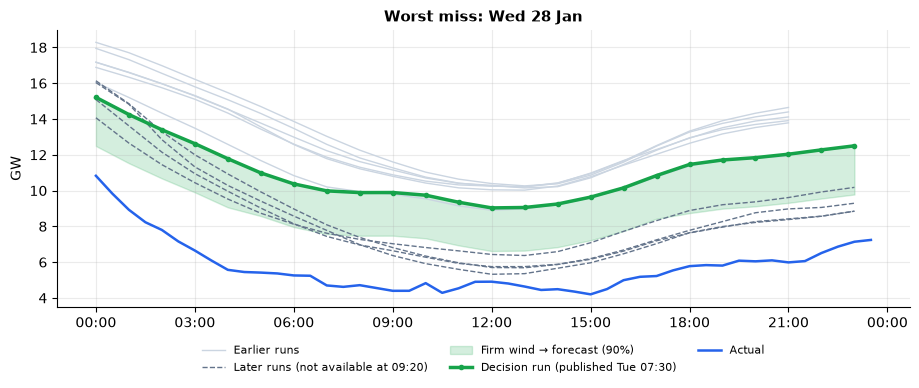

> At 09:20 on Tue 27 Jan, the latest forecast expected 267 GWh of wind for Wed 28 Jan. At 90% confidence you could count on an average of 8.6 GW. Wind delivered 138 GWh, 48% below forecast, with the largest shortfall of 6.2 GW at 04:00. Firm wind held in 0 of 24 hours.

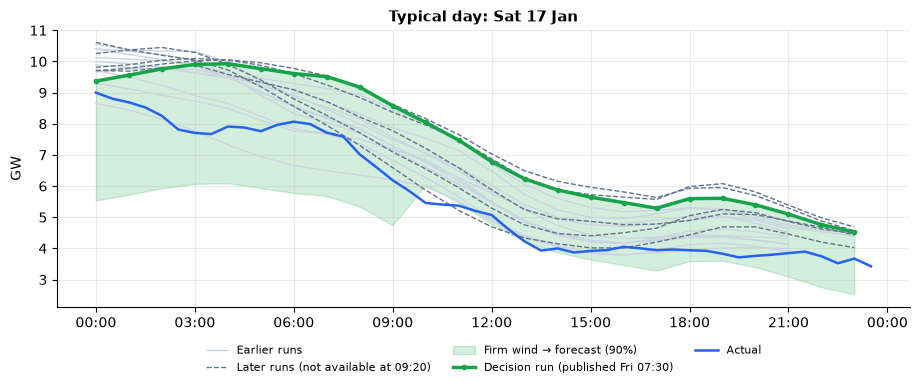

> At 09:20 on Fri 16 Jan, the latest forecast expected 177 GWh of wind for Sat 17 Jan. At 90% confidence you could count on an average of 4.6 GW. Wind delivered 136 GWh, 23% below forecast, with the largest shortfall of 2.6 GW at 10:00. Firm wind held in 21 of 24 hours.

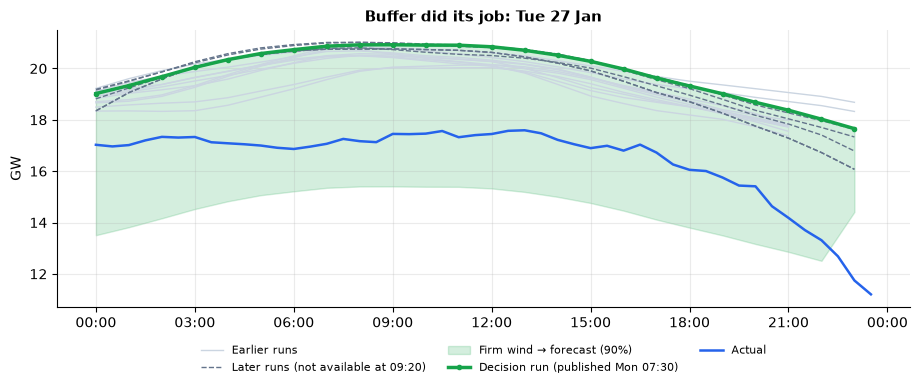

> At 09:20 on Mon 26 Jan, the latest forecast expected 477 GWh of wind for Tue 27 Jan. At 90% confidence you could count on an average of 14.5 GW. Wind delivered 394 GWh, 17% below forecast, with the largest shortfall of 5.9 GW at 23:00. Firm wind held in 23 of 24 hours.

In [19]:
def plot_day(d: date, title: str) -> None:
    r = results[d]
    _, ax = plt.subplots(figsize=(11, 3.6))
    earlier = [v for v in r.vintages if not v.is_decision_run and not v.after_cutoff]
    later = [v for v in r.vintages if v.after_cutoff]
    for i, v in enumerate(earlier):
        ax.plot(
            v.points["target_time"],
            v.points["forecast_mw"] / 1000,
            color=MUTED,
            lw=1,
            label="Earlier runs" if i == 0 else None,
        )
    for i, v in enumerate(later):
        ax.plot(
            v.points["target_time"],
            v.points["forecast_mw"] / 1000,
            color=SURPLUS,
            lw=1,
            ls="--",
            label="Later runs (not available at 09:20)" if i == 0 else None,
        )
    ax.fill_between(
        r.points["target_time"],
        r.points["firm_mw"] / 1000,
        r.points["forecast_mw"] / 1000,
        color=FORECAST,
        alpha=0.18,
        label="Firm wind → forecast (90%)",
    )
    ax.plot(
        r.points["target_time"],
        r.points["forecast_mw"] / 1000,
        color=FORECAST,
        lw=2.5,
        marker="o",
        ms=3,
        label=f"Decision run (published {r.run.publish_time.tz_convert(LONDON):%a %H:%M})",
    )
    ax.plot(
        r.actual["target_time"], r.actual["actual_mw"] / 1000, color=ACTUAL, lw=1.8, label="Actual"
    )
    ax.set(title=f"{title}: {day_label(d)}", ylabel="GW")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
    ax.legend(ncols=3, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.1))
    plt.show()
    display(Markdown(f"> {decision_summary(r)}"))


for title, d in story.items():
    plot_day(d, title)

In [20]:
w = acc.worst_hours(pools["epex"], 1).iloc[0]
answer(
    f"The worst decision hour was {uk(w['target_time'])}, forecast {mw(w['forecast_mw'])} vs actual "
    f"{mw(w['actual_mw'])} ({signed_mw(w['error_mw'])}, {w['lead_h']:g} h ahead). Story days: worst miss "
    f"{day_label(worst_day)} (MAE {mw(kpis.at[worst_day, 'mae_mw'])}), typical {day_label(typical_day)} "
    f"(MAE {mw(kpis.at[typical_day, 'mae_mw'])}), and {day_label(buffer_day)}, where wind came in "
    f"{kpis.at[buffer_day, 'energy_error_pct']:.0f}% below forecast but firm wind held in "
    f"{kpis.at[buffer_day, 'firm_kept']:.0f} of 24 hours."
)

**Answer:** The worst decision hour was Mon 12 Jan 01:00, forecast 20,942 MW vs actual 14,048 MW (+6,894 MW, 17.5 h ahead). Story days: worst miss Wed 28 Jan (MAE 5,329 MW), typical Sat 17 Jan (MAE 1,659 MW), and Tue 27 Jan, where wind came in 17% below forecast but firm wind held in 23 of 24 hours.

## 10. Reliability and the value of the forecast

**Question:** How much wind can the desk bank at a given confidence *with* the forecast, compared with what it
could bank knowing only January's distribution of wind (no forecast at all)?

,auction,unconditional_firm_mw,avg_forecast_firm_mw,gain_mw,confidence
0,epex,7513.0,10321.0,2808.0,1.0
1,epex,5380.0,9523.0,4143.0,1.0
2,epex,4285.0,8371.0,4087.0,1.0
3,n2ex,7513.0,10370.0,2857.0,1.0
4,n2ex,5380.0,9462.0,4083.0,1.0
5,n2ex,4285.0,8318.0,4033.0,1.0


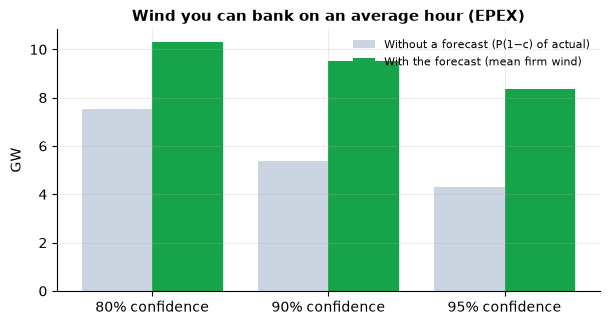

In [21]:
values = (
    pd.DataFrame(
        [
            {"auction": a, "confidence": c, **vars(acc.forecast_value(store.calibrations[(a, c)]))}
            for a in pools
            for c in CONFIDENCES
        ]
    )
    .drop(columns="confidence")
    .assign(confidence=[c for _ in pools for c in CONFIDENCES])
)
display(values.round(0))

ep_values = values[values["auction"] == "epex"]
fig, ax = plt.subplots(figsize=(7, 3.4))
x = np.arange(len(ep_values))
ax.bar(
    x - 0.2,
    ep_values["unconditional_firm_mw"] / 1000,
    0.4,
    color=MUTED,
    label="Without a forecast (P(1−c) of actual)",
)
ax.bar(
    x + 0.2,
    ep_values["avg_forecast_firm_mw"] / 1000,
    0.4,
    color=FORECAST,
    label="With the forecast (mean firm wind)",
)
ax.set(
    title="Wind you can bank on an average hour (EPEX)",
    xticks=x,
    xticklabels=[f"{100 * c:.0f}% confidence" for c in ep_values["confidence"]],
    ylabel="GW",
)
ax.legend(fontsize=8, loc="upper right")
plt.show()

In [22]:
v90 = values[(values["auction"] == "epex") & (values["confidence"] == C)].iloc[0]
answer(
    f"At 90% confidence the forecast lets the desk bank {mw(v90['avg_forecast_firm_mw'])} on an average hour, "
    f"against {mw(v90['unconditional_firm_mw'])} with no forecast: {signed_mw(v90['gain_mw'])}, despite the "
    f"forecast's upward bias (the buffer absorbs it)."
)

**Answer:** At 90% confidence the forecast lets the desk bank 9,523 MW on an average hour, against 5,380 MW with no forecast: +4,143 MW, despite the forecast's upward bias (the buffer absorbs it).

## 11. Conclusions → `docs/INSIGHTS.md`

**Question:** What are the headline numbers for the pitch? This cell writes them to `docs/INSIGHTS.md`; every number
there comes from the cells above.

In [23]:
cal = {a: store.calibrations[(a, C)].achieved_pct for a in pools}
lead_mae = {h: lc.at[h, "mae_mw"] for h in (1.5, 12.5, 24.5, 36.5, 47.5)}
e, n = metrics["epex"], metrics["n2ex"]


def story_line(i: int, title: str, d: date) -> str:
    k = kpis.loc[d]
    return (
        f"{i}) **{title}: {day_label(d)}**. MAE {mw(k['mae_mw'])}; forecast {k['forecast_gwh']:.0f} GWh vs actual "
        f"{k['actual_gwh']:.0f} GWh ({k['energy_error_pct']:+.0f}% shortfall); firm wind held "
        f"{k['firm_kept']:.0f}/24 h; largest shortfall {mw(k['max_shortfall_mw'])}. "
        f"Deep link: `/?date={d.isoformat()}&auction=epex&conf=0.9&view=hindsight`  \n   > {decision_summary(results[d])}"
    )


insights = f"""# Pilot insights: decisions made in January 2026

> Generated by `notebooks/01_wind_forecast_accuracy.ipynb` (`make notebook`) from snapshot `{store.snapshot_id}`.
> Do not edit by hand. Delivery days {day_label(store.delivery_days[0])} – {day_label(store.delivery_days[-1])}; 744 decision hours per auction.

| Metric (decision forecasts) | EPEX 09:20 | N2EX 09:50 |
|---|---|---|
| MAE (MW) / WAPE (%) | {e.mae_mw:,.0f} / {e.wape_pct:.1f} | {n.mae_mw:,.0f} / {n.wape_pct:.1f} |
| Bias (MW, + = over-forecast) | {e.bias_mw:+,.0f} | {n.bias_mw:+,.0f} |
| P90 buffer (MW), pool-wide P90 shortfall | {e.p90_shortfall_mw:,.0f} | {n.p90_shortfall_mw:,.0f} |
| P90 buffer (MW), average conditional LODO buffer applied | {cal90.at["epex", "avg conditional buffer (MW)"]:,.0f} | {cal90.at["n2ex", "avg conditional buffer (MW)"]:,.0f} |
| P90 firm-wind achieved coverage (%) | {cal["epex"]:.1f} | {cal["n2ex"]:.1f} |

Lead curve MAE (MW): 1.5 h {lead_mae[1.5]:,.0f} · 12.5 h {lead_mae[12.5]:,.0f} · 24.5 h {lead_mae[24.5]:,.0f} · 36.5 h {lead_mae[36.5]:,.0f} · 47.5 h {lead_mae[47.5]:,.0f}

Value of the forecast @90% (EPEX): no-forecast firm {v90["unconditional_firm_mw"]:,.0f} MW → forecast firm {v90["avg_forecast_firm_mw"]:,.0f} MW ({v90["gain_mw"]:+,.0f} MW)

Auction timing: moving from the EPEX 09:20 to the N2EX 09:50 cutoff (the 09:30 run) changes MAE by {cmp.mae_change_pct:+.1f}% ({mw(e.mae_mw)} → {mw(n.mae_mw)}).

Buffer method at 90% (EPEX): conditional LODO holds back {mw(cal90.at["epex", "avg conditional buffer (MW)"])} on average for {cal90.at["epex", "conditional achieved %"]:.1f}% coverage; one flat LODO buffer holds back {mw(cal90.at["epex", "simple buffer, avg (MW)"])} for {cal90.at["epex", "simple achieved %"]:.1f}%.

Calibration (conditional LODO), target → achieved: {"; ".join(f"{r['auction'].upper()} {r['target %']:.0f}% → {r['conditional achieved %']:.1f}%" for _, r in calibration.iterrows())}.

## Story days
{story_line(1, "Worst miss", worst_day)}

{story_line(2, "Typical day", typical_day)}

{story_line(3, "Buffer did its job", buffer_day)}

## Three pitch sentences
1. At your 09:20 cutoff, tomorrow's wind forecast is typically off by {mw(e.mae_mw)}, and it runs high: {mw(e.bias_mw)} too high on average, with wind below forecast in {tails["share over-forecast (%)"]:.0f}% of hours.
2. Planning on P90 firm wind instead of the point forecast held in {cal["epex"]:.0f}% of hours in a back-test that never looks ahead (target 90%).
3. With the forecast you can bank {mw(v90["gain_mw"])} more wind on an average hour than without it ({mw(v90["avg_forecast_firm_mw"])} vs {mw(v90["unconditional_firm_mw"])}), while bidding at 09:50 instead of 09:20 {"improves" if cmp.mae_change_pct < 0 else "changes"} accuracy by only {abs(cmp.mae_change_pct):.1f}%.

## Findings to state honestly
- **Systematic over-forecast.** Bias is {signed_mw(lc.at[0.5, "bias_mw"])} even 0.5 h ahead and grows with wind level ({signed_mw(levels["bias_mw"].iloc[0])} in the lowest forecast quintile → {signed_mw(levels["bias_mw"].iloc[-1])} in the highest); actual ≈ {intercept:,.0f} + {slope:.2f} × forecast. It is consistent with constraint curtailment or a scope difference between WINDFOR and FUELHH; Elexon's dataset descriptions do not settle it, so it is a hypothesis to confirm with the client. The buffers absorb it, which is why calibration holds.
- **One off-schedule run:** {", ".join(off_schedule)} UTC (the 11:30 slot on 15 Jan). It is kept as published and is not a decision run for either auction.
- **Alignment:** comparing with the hourly mean instead of the period starting at H changes EPEX MAE by {d_mae:+,.0f} MW; {"no headline conclusion changes" if not changed else "changed: " + ", ".join(changed)}.
- **Sample size:** one month (744 decision hours per auction). P95 is a small-sample estimate; P99 is not offered as a buffer.
"""
(REPO_ROOT / "docs" / "INSIGHTS.md").write_text(insights, encoding="utf-8")
display(Markdown(insights))

# Pilot insights: decisions made in January 2026

> Generated by `notebooks/01_wind_forecast_accuracy.ipynb` (`make notebook`) from snapshot `ac22a4140bca`.
> Do not edit by hand. Delivery days Fri 2 Jan – Sun 1 Feb; 744 decision hours per auction.

| Metric (decision forecasts) | EPEX 09:20 | N2EX 09:50 |
|---|---|---|
| MAE (MW) / WAPE (%) | 2,022 / 17.9 | 1,996 / 17.7 |
| Bias (MW, + = over-forecast) | +1,746 | +1,728 |
| P90 buffer (MW), pool-wide P90 shortfall | 4,154 | 4,184 |
| P90 buffer (MW), average conditional LODO buffer applied | 3,509 | 3,551 |
| P90 firm-wind achieved coverage (%) | 87.0 | 87.2 |

Lead curve MAE (MW): 1.5 h 1,667 · 12.5 h 1,740 · 24.5 h 1,949 · 36.5 h 2,078 · 47.5 h 2,405

Value of the forecast @90% (EPEX): no-forecast firm 5,380 MW → forecast firm 9,523 MW (+4,143 MW)

Auction timing: moving from the EPEX 09:20 to the N2EX 09:50 cutoff (the 09:30 run) changes MAE by -1.3% (2,022 MW → 1,996 MW).

Buffer method at 90% (EPEX): conditional LODO holds back 3,509 MW on average for 87.0% coverage; one flat LODO buffer holds back 4,142 MW for 88.6%.

Calibration (conditional LODO), target → achieved: EPEX 80% → 77.7%; EPEX 90% → 87.0%; EPEX 95% → 92.6%; N2EX 80% → 78.5%; N2EX 90% → 87.2%; N2EX 95% → 92.3%.

## Story days
1) **Worst miss: Wed 28 Jan**. MAE 5,329 MW; forecast 267 GWh vs actual 138 GWh (+48% shortfall); firm wind held 0/24 h; largest shortfall 6,210 MW. Deep link: `/?date=2026-01-28&auction=epex&conf=0.9&view=hindsight`  
   > At 09:20 on Tue 27 Jan, the latest forecast expected 267 GWh of wind for Wed 28 Jan. At 90% confidence you could count on an average of 8.6 GW. Wind delivered 138 GWh, 48% below forecast, with the largest shortfall of 6.2 GW at 04:00. Firm wind held in 0 of 24 hours.

2) **Typical day: Sat 17 Jan**. MAE 1,659 MW; forecast 177 GWh vs actual 136 GWh (+23% shortfall); firm wind held 21/24 h; largest shortfall 2,587 MW. Deep link: `/?date=2026-01-17&auction=epex&conf=0.9&view=hindsight`  
   > At 09:20 on Fri 16 Jan, the latest forecast expected 177 GWh of wind for Sat 17 Jan. At 90% confidence you could count on an average of 4.6 GW. Wind delivered 136 GWh, 23% below forecast, with the largest shortfall of 2.6 GW at 10:00. Firm wind held in 21 of 24 hours.

3) **Buffer did its job: Tue 27 Jan**. MAE 3,419 MW; forecast 477 GWh vs actual 394 GWh (+17% shortfall); firm wind held 23/24 h; largest shortfall 5,914 MW. Deep link: `/?date=2026-01-27&auction=epex&conf=0.9&view=hindsight`  
   > At 09:20 on Mon 26 Jan, the latest forecast expected 477 GWh of wind for Tue 27 Jan. At 90% confidence you could count on an average of 14.5 GW. Wind delivered 394 GWh, 17% below forecast, with the largest shortfall of 5.9 GW at 23:00. Firm wind held in 23 of 24 hours.

## Three pitch sentences
1. At your 09:20 cutoff, tomorrow's wind forecast is typically off by 2,022 MW, and it runs high: 1,746 MW too high on average, with wind below forecast in 85% of hours.
2. Planning on P90 firm wind instead of the point forecast held in 87% of hours in a back-test that never looks ahead (target 90%).
3. With the forecast you can bank 4,143 MW more wind on an average hour than without it (9,523 MW vs 5,380 MW), while bidding at 09:50 instead of 09:20 improves accuracy by only 1.3%.

## Findings to state honestly
- **Systematic over-forecast.** Bias is +1,455 MW even 0.5 h ahead and grows with wind level (+371 MW in the lowest forecast quintile → +3,458 MW in the highest); actual ≈ 737 + 0.81 × forecast. It is consistent with constraint curtailment or a scope difference between WINDFOR and FUELHH; Elexon's dataset descriptions do not settle it, so it is a hypothesis to confirm with the client. The buffers absorb it, which is why calibration holds.
- **One off-schedule run:** Thu 15 Jan 12:25 UTC (the 11:30 slot on 15 Jan). It is kept as published and is not a decision run for either auction.
- **Alignment:** comparing with the hourly mean instead of the period starting at H changes EPEX MAE by +16 MW; no headline conclusion changes.
- **Sample size:** one month (744 decision hours per auction). P95 is a small-sample estimate; P99 is not offered as a buffer.


In [24]:
answer(
    f"Day-ahead wind error is about {mw(e.mae_mw)} with a {signed_mw(e.bias_mw)} upward bias; a leave-one-day-out P90 "
    f"buffer holds in {cal['epex']:.1f}% of hours and lets the desk bank {mw(v90['avg_forecast_firm_mw'])} on an average "
    f"hour, {mw(v90['gain_mw'])} more than without a forecast. `docs/INSIGHTS.md` has been written."
)

**Answer:** Day-ahead wind error is about 2,022 MW with a +1,746 MW upward bias; a leave-one-day-out P90 buffer holds in 87.0% of hours and lets the desk bank 9,523 MW on an average hour, 4,143 MW more than without a forecast. `docs/INSIGHTS.md` has been written.